# Bayesian Logistic Regression with a Laplace Approximation

This notebook is designed for a seminar/demo. It accompanies the PDF notes and is intentionally self-contained: only **NumPy, SciPy, Matplotlib and pandas** are used.

### What we will demonstrate
1. Laplace approximation for a one-dimensional non-Gaussian density.
2. MAP estimation for Bayesian logistic regression via Newton's method.
3. The Laplace posterior: mode + inverse negative Hessian.
4. Comparison of the Laplace approximation with a dense-grid posterior in 2 parameters.
5. Posterior predictive probabilities and uncertainty.
6. Why a Gaussian prior helps under (near) complete separation.
7. The maximum-entropy property of a Gaussian at fixed variance.

All random examples use fixed seeds so the figures are reproducible.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.linalg import solve, inv, slogdet
from scipy.special import expit, logsumexp
from scipy.optimize import minimize_scalar
from scipy.stats import norm
from numpy.polynomial.hermite import hermgauss

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(7)


## 1. Warm-up: Laplace approximation in one dimension

Suppose an unnormalized density is

$$
p(z) = \frac{1}{Z} f(z),\qquad Z=\int f(z)\,dz.
$$

Let $z_0$ be the mode of $\log f(z)$. A second-order Taylor expansion gives

$$
\log f(z) \approx \log f(z_0)-\frac12 A(z-z_0)^2,
\qquad
A=-\left.\frac{d^2}{dz^2}\log f(z)\right|_{z=z_0}>0.
$$

Therefore

$$
p(z)\approx q(z)=\mathcal N(z\mid z_0,A^{-1}),
\qquad
Z\approx f(z_0)\sqrt{\frac{2\pi}{A}}.
$$

The approximation is **local**: it matches the mode and local curvature, not necessarily the tails or skewness.


mode z0 = 1.2073
local precision A = 2.0220; variance = 0.4946
normalizer from grid    = 0.0098475
Laplace normalizer      = 0.00960116
relative Z error        = -2.50%


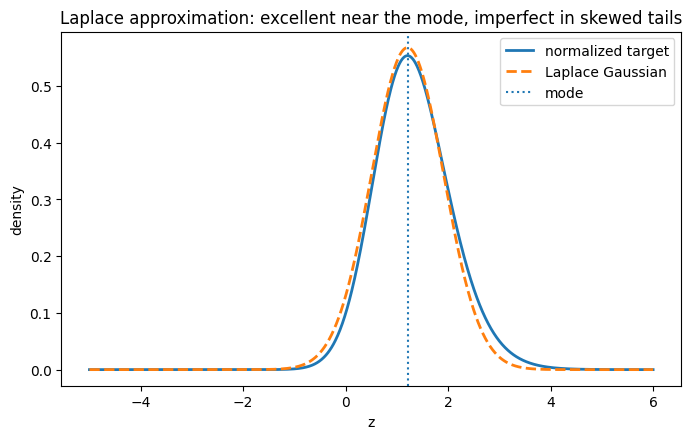

In [4]:
# A deliberately skewed, non-Gaussian target with full real support.
# Think of it as a Gaussian prior multiplied by a Bernoulli/binomial-like likelihood.
def log_f_1d(z):
    # Gaussian prior N(0, 2^2), plus 8 successes and 2 failures with logit z
    return -0.5 * (z / 2.0)**2 + 8*np.log(expit(z)) + 2*np.log(expit(-z))

res = minimize_scalar(lambda z: -log_f_1d(z), bracket=(-3, 3))
z0 = res.x

# Numerical second derivative at the mode
h = 1e-4
second = (log_f_1d(z0+h) - 2*log_f_1d(z0) + log_f_1d(z0-h)) / h**2
A = -second
var_laplace = 1.0 / A

z = np.linspace(-5, 6, 1200)
logf = log_f_1d(z)
logZ_grid = logsumexp(logf) + np.log(z[1]-z[0])
p_exact = np.exp(logf - logZ_grid)
p_laplace = norm.pdf(z, loc=z0, scale=np.sqrt(var_laplace))

Z_laplace = np.exp(log_f_1d(z0)) * np.sqrt(2*np.pi/A)
Z_grid = np.exp(logZ_grid)

print(f"mode z0 = {z0:.4f}")
print(f"local precision A = {A:.4f}; variance = {var_laplace:.4f}")
print(f"normalizer from grid    = {Z_grid:.6g}")
print(f"Laplace normalizer      = {Z_laplace:.6g}")
print(f"relative Z error        = {(Z_laplace/Z_grid - 1):+.2%}")

plt.figure(figsize=(8, 4.6))
plt.plot(z, p_exact, lw=2, label='normalized target')
plt.plot(z, p_laplace, '--', lw=2, label='Laplace Gaussian')
plt.axvline(z0, ls=':', label='mode')
plt.xlabel('z')
plt.ylabel('density')
plt.title('Laplace approximation: excellent near the mode, imperfect in skewed tails')
plt.legend()
plt.show()


### Board takeaway
For $d$ dimensions, if

$$
A=-\nabla^2 \log f(z_0),
$$

then

$$
q(z)=\mathcal N(z\mid z_0,A^{-1}),
\qquad
Z\approx f(z_0)(2\pi)^{d/2}|A|^{-1/2}.
$$

A useful mnemonic is: **negative Hessian = precision; inverse negative Hessian = covariance**.


## 2. Bayesian logistic regression: model and derivatives

For observations $(x_i,y_i)$ with $y_i\in\{0,1\}$, use a design matrix $X$ (we include an intercept column) and

$$
p(y_i=1\mid x_i,\theta)=\sigma(x_i^\top\theta),
\qquad \sigma(a)=\frac{1}{1+e^{-a}}.
$$

With a Gaussian prior

$$
\theta\sim\mathcal N(m_0,S_0),\qquad P_0=S_0^{-1},
$$

the log posterior, up to an additive constant, is

$$
\ell(\theta)
= y^\top X\theta - \sum_i\log(1+e^{x_i^\top\theta})
-\frac12(\theta-m_0)^\top P_0(\theta-m_0).
$$

If $p=\sigma(X\theta)$ and $W=\operatorname{diag}(p_i(1-p_i))$, then

$$
\nabla\ell(\theta)=X^\top(y-p)-P_0(\theta-m_0),
$$

$$
\nabla^2\ell(\theta)=-X^\top W X-P_0.
$$

Thus the negative Hessian is positive definite whenever the prior precision is positive definite. Newton's maximization update can be written as

$$
\theta_{\text{new}}=\theta_{\text{old}} + A(\theta_{\text{old}})^{-1}\nabla\ell(\theta_{\text{old}}),
\quad
A=X^\top W X+P_0.
$$


In [5]:
def add_intercept(x):
    x = np.asarray(x)
    if x.ndim == 1:
        x = x[:, None]
    return np.column_stack([np.ones(len(x)), x])


def log_posterior(theta, X, y, m0, P0):
    eta = X @ theta
    # log sigmoid likelihood, computed stably with logaddexp
    loglik = np.sum(y*eta - np.logaddexp(0.0, eta))
    d = theta - m0
    logprior_kernel = -0.5 * d @ P0 @ d
    return loglik + logprior_kernel


def grad_and_precision(theta, X, y, m0, P0):
    p = expit(X @ theta)
    w = p * (1-p)
    grad = X.T @ (y-p) - P0 @ (theta-m0)
    A = X.T @ (w[:, None] * X) + P0  # A = -Hessian
    return grad, A


def fit_map_newton(X, y, m0, S0, theta_init=None, tol=1e-10, max_iter=100):
    P0 = inv(S0)
    theta = np.array(m0 if theta_init is None else theta_init, dtype=float).copy()
    trace = []
    old_lp = log_posterior(theta, X, y, m0, P0)

    for it in range(max_iter):
        grad, A = grad_and_precision(theta, X, y, m0, P0)
        step = solve(A, grad)  # because H = -A, Newton-max step = A^{-1} grad

        # Backtracking makes the demo robust even from a poor starting point.
        t = 1.0
        while t > 1e-8:
            candidate = theta + t*step
            new_lp = log_posterior(candidate, X, y, m0, P0)
            if new_lp >= old_lp:
                break
            t *= 0.5

        theta = candidate
        trace.append((it, new_lp, np.linalg.norm(grad), np.linalg.norm(t*step)))
        if np.linalg.norm(t*step) < tol:
            break
        old_lp = new_lp

    _, A_map = grad_and_precision(theta, X, y, m0, P0)
    S_laplace = inv(A_map)
    return theta, S_laplace, pd.DataFrame(trace, columns=['iter','log posterior','||grad||','||step||'])


## 3. Toy data: one predictor + intercept

This two-parameter case is useful pedagogically because we can compute a high-resolution posterior on a grid and compare it directly with the Laplace Gaussian.


In [8]:
rng = np.random.default_rng(14)
n = 360000
x = np.linspace(-2.5, 2.5, n)
theta_true = np.array([-0.35, 1.75])
X = add_intercept(x)
prob_true = expit(X @ theta_true)
y = rng.binomial(1, prob_true)

m0 = np.zeros(2)
prior_sd = np.array([2.5, 2.5])
S0 = np.diag(prior_sd**2)

theta_map, S_laplace, trace = fit_map_newton(X, y, m0, S0)

print('theta_true =', theta_true)
print('theta_MAP  =', theta_map)
print('Laplace posterior covariance:\n', S_laplace)
trace


theta_true = [-0.35  1.75]
theta_MAP  = [-0.3487  1.7458]
Laplace posterior covariance:
 [[ 0. -0.]
 [-0.  0.]]


,iter,log posterior,||grad||,||step||
0,0,-142167.089981,1.886273e+05,1.015234e+00
1,1,-130116.015150,4.194671e+04,4.929800e-01
2,2,-128791.307041,1.057185e+04,2.323640e-01
3,3,-128762.616425,1.392702e+03,4.097194e-02
4,4,-128762.598440,3.426413e+01,1.060571e-03
5,5,-128762.598440,2.208463e-02,6.847477e-07
6,6,-128762.598440,9.193939e-09,3.564403e-14


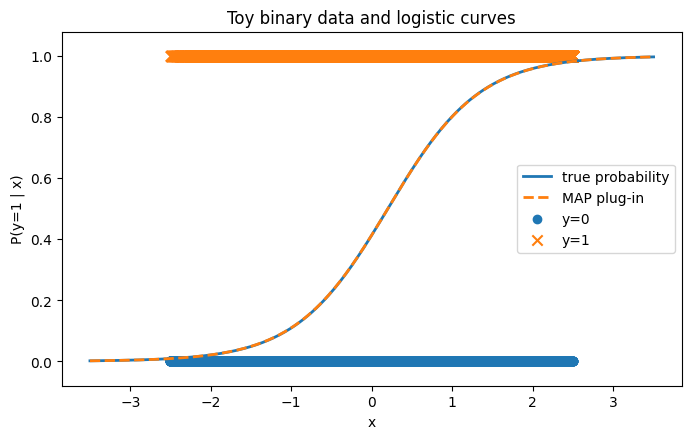

In [9]:
# Visualize data and the MAP fit.
xx = np.linspace(-3.5, 3.5, 400)
XX = add_intercept(xx)

plt.figure(figsize=(8, 4.6))
plt.scatter(x[y==0], y[y==0], marker='o', label='y=0')
plt.scatter(x[y==1], y[y==1], marker='x', s=55, label='y=1')
plt.plot(xx, expit(XX @ theta_true), lw=2, label='true probability')
plt.plot(xx, expit(XX @ theta_map), '--', lw=2, label='MAP plug-in')
plt.ylim(-0.08, 1.08)
plt.xlabel('x')
plt.ylabel('P(y=1 | x)')
plt.title('Toy binary data and logistic curves')
plt.legend()
plt.show()


## 4. Exact-on-a-grid posterior vs. Laplace posterior

For two parameters we can numerically normalize the posterior on a dense grid. This is not a general inference method, but it is an excellent **sanity check** for Laplace.


In [ ]:
# Grid around the MAP, wide enough to show posterior geometry.
sd = np.sqrt(np.diag(S_laplace))
b0_grid = np.linspace(theta_map[0]-4*sd[0], theta_map[0]+4*sd[0], 260)
b1_grid = np.linspace(theta_map[1]-4*sd[1], theta_map[1]+4*sd[1], 260)
B0, B1 = np.meshgrid(b0_grid, b1_grid)
pts = np.column_stack([B0.ravel(), B1.ravel()])
P0 = inv(S0)

logpost = np.array([log_posterior(t, X, y, m0, P0) for t in pts]).reshape(B0.shape)
logpost -= logpost.max()
post = np.exp(logpost)
post /= np.trapz(np.trapz(post, b0_grid, axis=1), b1_grid, axis=0)

# Laplace density on the same grid
Sinv = inv(S_laplace)
detS = np.linalg.det(S_laplace)
diff = pts - theta_map
quad = np.einsum('ni,ij,nj->n', diff, Sinv, diff)
q = np.exp(-0.5*quad) / (2*np.pi*np.sqrt(detS))
q = q.reshape(B0.shape)

levels_post = np.quantile(post[post > post.max()*1e-4], [0.35, 0.60, 0.78, 0.90])
levels_q = np.quantile(q[q > q.max()*1e-4], [0.35, 0.60, 0.78, 0.90])

plt.figure(figsize=(7, 6))
plt.contour(B0, B1, post, levels=np.unique(levels_post), linewidths=2)
plt.contour(B0, B1, q, levels=np.unique(levels_q), linestyles='--', linewidths=1.8)
plt.scatter([theta_map[0]], [theta_map[1]], marker='*', s=120, label='MAP')
plt.scatter([theta_true[0]], [theta_true[1]], marker='x', s=80, label='true parameter')
plt.xlabel(r'$\theta_0$ (intercept)')
plt.ylabel(r'$\theta_1$ (slope)')
plt.title('Posterior contours (solid) vs Laplace Gaussian (dashed)')
plt.legend()
plt.show()


In [7]:
# Compare posterior moments from the grid with Laplace mode/covariance.
db0 = b0_grid[1]-b0_grid[0]
db1 = b1_grid[1]-b1_grid[0]
weights = post.ravel() * db0 * db1
weights /= weights.sum()
mean_grid = np.sum(pts * weights[:, None], axis=0)
dg = pts - mean_grid
cov_grid = (dg * weights[:, None]).T @ dg

comparison = pd.DataFrame({
    'grid posterior mean': mean_grid,
    'Laplace center (MAP)': theta_map,
    'grid posterior sd': np.sqrt(np.diag(cov_grid)),
    'Laplace sd': np.sqrt(np.diag(S_laplace)),
}, index=['intercept', 'slope'])
comparison


,grid posterior mean,Laplace center (MAP),grid posterior sd,Laplace sd
intercept,-0.305246,-0.269896,0.556589,0.524815
slope,2.226887,1.948130,0.641918,0.597145


### What to point out live
- The approximation is centered at the **mode**, not at the exact posterior mean.
- It uses only **local curvature** at the mode.
- When the posterior is close to elliptical and unimodal, the match is often good.
- With strong skewness, weak data, multimodality, or boundaries, Laplace can be misleading.


## 5. Posterior prediction: integrate over parameter uncertainty

The Bayesian predictive probability is

$$
p(y_*=1\mid x_*,\mathcal D)
=\int \sigma(x_*^\top\theta)\,p(\theta\mid\mathcal D)\,d\theta.
$$

Under the Laplace approximation $q(\theta)=\mathcal N(\theta_{MAP},S)$, the scalar

$$
a_*=x_*^\top\theta
$$

is Gaussian with mean $m_*=x_*^\top\theta_{MAP}$ and variance $v_*=x_*^\top Sx_*$. The remaining logistic-normal integral has no elementary closed form.

We will compare:
1. Monte Carlo over $q(\theta)$;
2. Gauss-Hermite quadrature in the one-dimensional $a_*$ distribution;
3. the common approximation

$$
\mathbb E[\sigma(a_*)]\approx
\sigma\!\left(\frac{m_*}{\sqrt{1+\pi v_*/8}}\right).
$$


max |Gauss-Hermite - Monte Carlo| = 0.001306774552688017
max |analytic approx - Gauss-Hermite| = 0.008392023386792902


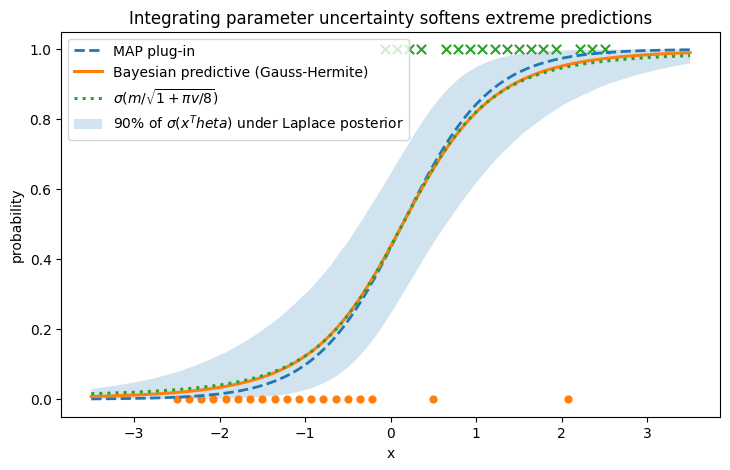

In [8]:
def predictive_gh(Xnew, mean, cov, n_nodes=40):
    nodes, weights = hermgauss(n_nodes)
    out = []
    for xrow in Xnew:
        m = xrow @ mean
        v = xrow @ cov @ xrow
        a = m + np.sqrt(2*v) * nodes
        out.append(np.sum(weights * expit(a)) / np.sqrt(np.pi))
    return np.array(out)


def predictive_mackay(Xnew, mean, cov):
    m = Xnew @ mean
    v = np.einsum('ni,ij,nj->n', Xnew, cov, Xnew)
    return expit(m / np.sqrt(1 + np.pi*v/8))

rng = np.random.default_rng(123)
samples = rng.multivariate_normal(theta_map, S_laplace, size=8000)
prob_samples = expit(XX @ samples.T)
p_mc = prob_samples.mean(axis=1)
p_lo, p_hi = np.quantile(prob_samples, [0.05, 0.95], axis=1)
p_gh = predictive_gh(XX, theta_map, S_laplace)
p_approx = predictive_mackay(XX, theta_map, S_laplace)
p_plugin = expit(XX @ theta_map)

print('max |Gauss-Hermite - Monte Carlo| =', np.max(np.abs(p_gh-p_mc)))
print('max |analytic approx - Gauss-Hermite| =', np.max(np.abs(p_approx-p_gh)))

plt.figure(figsize=(8.5, 5.0))
plt.fill_between(xx, p_lo, p_hi, alpha=0.20, label='90% of $\sigma(x^T\theta)$ under Laplace posterior')
plt.plot(xx, p_plugin, '--', lw=2, label='MAP plug-in')
plt.plot(xx, p_gh, lw=2.2, label='Bayesian predictive (Gauss-Hermite)')
plt.plot(xx, p_approx, ':', lw=2.2, label=r'$\sigma(m/\sqrt{1+\pi v/8})$')
plt.scatter(x[y==0], y[y==0], marker='o', s=24)
plt.scatter(x[y==1], y[y==1], marker='x', s=45)
plt.ylim(-0.05, 1.05)
plt.xlabel('x')
plt.ylabel('probability')
plt.title('Integrating parameter uncertainty softens extreme predictions')
plt.legend(loc='best')
plt.show()


## 6. Prior sensitivity and complete separation

In ordinary logistic regression, completely separable data can make the MLE coefficients diverge: the likelihood keeps improving as the separating slope grows.

A proper Gaussian prior changes the objective. The quadratic log-prior eventually dominates, so the posterior has a finite mode. This is both a practical regularization effect and an important Bayesian example of how prior information resolves an ill-posed likelihood problem.


In [9]:
# Perfectly separated toy data
x_sep = np.r_[np.linspace(-3, -0.25, 15), np.linspace(0.25, 3, 15)]
y_sep = np.r_[np.zeros(15), np.ones(15)]
X_sep = add_intercept(x_sep)

rows=[]
fits={}
for sd_prior in [0.75, 1.5, 3.0, 8.0]:
    S0_sep = np.diag([sd_prior**2, sd_prior**2])
    th, cov, tr = fit_map_newton(X_sep, y_sep, np.zeros(2), S0_sep)
    rows.append((sd_prior, th[0], th[1], np.sqrt(cov[1,1])))
    fits[sd_prior]=(th,cov)

pd.DataFrame(rows, columns=['prior sd','MAP intercept','MAP slope','posterior sd(slope)'])


,prior sd,MAP intercept,MAP slope,posterior sd(slope)
0,0.75,6.196868e-17,1.641620,0.446132
1,1.50,1.754756e-16,2.624097,0.858847
2,3.00,7.201064e-17,4.097725,1.683786
3,8.00,-3.491276e-16,7.393082,4.251220


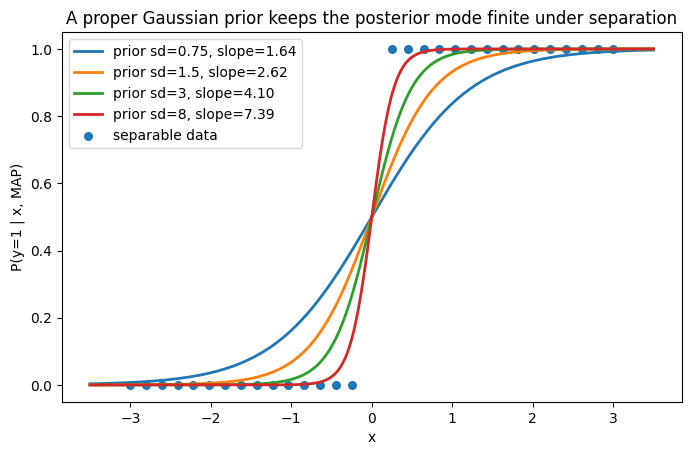

In [10]:
xx_sep = np.linspace(-3.5, 3.5, 400)
XX_sep = add_intercept(xx_sep)
plt.figure(figsize=(8, 4.8))
plt.scatter(x_sep, y_sep, s=30, label='separable data')
for sd_prior, (th, cov) in fits.items():
    plt.plot(xx_sep, expit(XX_sep@th), lw=2, label=f'prior sd={sd_prior:g}, slope={th[1]:.2f}')
plt.ylim(-0.05,1.05)
plt.xlabel('x')
plt.ylabel('P(y=1 | x, MAP)')
plt.title('A proper Gaussian prior keeps the posterior mode finite under separation')
plt.legend()
plt.show()


## 7. Maximum entropy at fixed variance

For a continuous density $p$ on $\mathbb R$, differential entropy is

$$
h(p)=-\int p(x)\log p(x)\,dx.
$$

Let $p$ have finite variance $\sigma^2$ and mean $\mu$, and let

$$
\phi(x)=\mathcal N(x\mid\mu,\sigma^2).
$$

Non-negativity of KL divergence gives

$$
D_{KL}(p\|\phi)
=\int p\log\frac{p}{\phi}\,dx\ge 0.
$$

Now

$$
\mathbb E_p[\log\phi(X)]
=-\frac12\log(2\pi\sigma^2)
-\frac{1}{2\sigma^2}\mathbb E_p[(X-\mu)^2]
=-\frac12\log(2\pi\sigma^2)-\frac12.
$$

Therefore

$$
D_{KL}(p\|\phi)
=-h(p)+\frac12\log(2\pi e\sigma^2)\ge0,
$$

so

$$
\boxed{h(p)\le \tfrac12\log(2\pi e\sigma^2)}.
$$

Equality holds iff $p=\phi$ almost everywhere. Because differential entropy is translation-invariant, fixing the variance alone is enough; the maximizing Gaussian may have any mean.


In [11]:
# Compare several zero-mean, unit-variance distributions.
xh = np.linspace(-4.5, 4.5, 1500)

# N(0,1)
p_gauss = norm.pdf(xh)
h_gauss = 0.5*np.log(2*np.pi*np.e)

# Laplace variance = 2 b^2 -> b=1/sqrt(2)
b = 1/np.sqrt(2)
p_laplace = np.exp(-np.abs(xh)/b)/(2*b)
h_laplace = 1 + np.log(2*b)

# Uniform on [-sqrt(3), sqrt(3)] has variance 1
a = np.sqrt(3)
p_uniform = np.where(np.abs(xh)<=a, 1/(2*a), 0.0)
h_uniform = np.log(2*a)

# Logistic scale s has variance pi^2 s^2/3; choose s=sqrt(3)/pi
s = np.sqrt(3)/np.pi
u = xh/s
p_logistic = np.exp(-u)/(s*(1+np.exp(-u))**2)
h_logistic = np.log(s) + 2

entropy_table = pd.DataFrame({
    'distribution': ['Gaussian', 'Logistic (scaled)', 'Laplace (scaled)', 'Uniform (scaled)'],
    'variance': [1,1,1,1],
    'differential entropy (nats)': [h_gauss, h_logistic, h_laplace, h_uniform]
}).sort_values('differential entropy (nats)', ascending=False)
entropy_table


,distribution,variance,differential entropy (nats)
0,Gaussian,1,1.418939
1,Logistic (scaled),1,1.404576
2,Laplace (scaled),1,1.346574
3,Uniform (scaled),1,1.242453


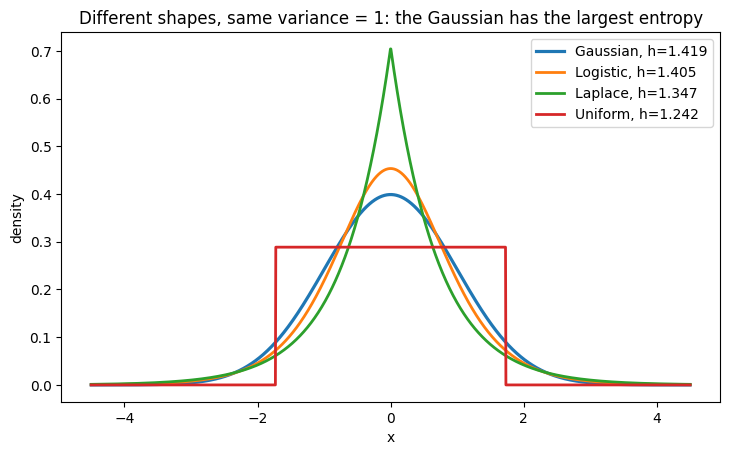

In [12]:
plt.figure(figsize=(8.5, 4.8))
plt.plot(xh, p_gauss, lw=2.3, label=f'Gaussian, h={h_gauss:.3f}')
plt.plot(xh, p_logistic, lw=2, label=f'Logistic, h={h_logistic:.3f}')
plt.plot(xh, p_laplace, lw=2, label=f'Laplace, h={h_laplace:.3f}')
plt.plot(xh, p_uniform, lw=2, label=f'Uniform, h={h_uniform:.3f}')
plt.xlabel('x')
plt.ylabel('density')
plt.title('Different shapes, same variance = 1: the Gaussian has the largest entropy')
plt.legend()
plt.show()


### Why this theorem is useful here

- **Gaussian prior as a weakly committal choice given only first/second moments.** If all you want to encode is a mean and covariance, the Gaussian adds no extra shape constraints in the maximum-entropy sense.
- **Regularization in logistic regression.** A Gaussian prior produces the familiar quadratic penalty and gives a finite posterior mode even when the likelihood is separated.
- **Local Gaussian approximations.** Laplace is not *derived* from maximum entropy; it is derived from a second-order Taylor expansion. But once we summarize local uncertainty using a covariance, a Gaussian is a natural least-structured distribution with that covariance.
- **Communications/information theory.** Under an average power (variance) constraint, Gaussian signals maximize differential entropy; with additive Gaussian noise this fact underlies the Gaussian channel capacity result.

### Important caveats
- Differential entropy is not the same object as discrete Shannon entropy and can be negative.
- The result depends on the constraint. With only bounded support fixed, the **uniform** distribution maximizes entropy.
- If covariance is fixed in $d$ dimensions, the multivariate version is

$$
h(p)\le \frac12\log\big((2\pi e)^d\det\Sigma\big),
$$

with equality only for $\mathcal N(\mu,\Sigma)$.


## 8. A compact seminar algorithm

**Input:** $X,y$, prior $\mathcal N(m_0,S_0)$.

1. Initialize $\theta$.
2. Repeat until convergence:
   - $p\leftarrow \sigma(X\theta)$;
   - $W\leftarrow \operatorname{diag}(p_i(1-p_i))$;
   - $g\leftarrow X^\top(y-p)-S_0^{-1}(\theta-m_0)$;
   - $A\leftarrow X^\top W X+S_0^{-1}$;
   - $\theta\leftarrow \theta+A^{-1}g$ (with line search if desired).
3. Set $\theta_{MAP}=\theta$ and $S=A^{-1}$.
4. Use $q(\theta)=\mathcal N(\theta_{MAP},S)$ for posterior summaries.
5. For prediction, integrate $\sigma(x_*^\top\theta)$ over $q$ using Gauss-Hermite, Monte Carlo, or the approximation $\sigma(m_*/\sqrt{1+\pi v_*/8})$.

### Diagnostic questions for the audience
- What exactly does the Hessian measure geometrically?
- Why does uncertainty get larger away from observed $x$ values?
- Why is the predictive mean not generally equal to $\sigma(x^\top\theta_{MAP})$?
- What can go wrong if the posterior is multimodal or strongly skewed?
- Which part of this notebook would fail first in a high-dimensional neural network?


## 9. Optional exercise: change the prior and data size

Try these live:
- Set `prior_sd = [0.5, 0.5]` and rerun Sections 3-5.
- Increase the data size from `n=36` to `n=300`.
- Move all observed `x` values close to zero, then inspect predictive uncertainty far from zero.
- Create almost-separable data and compare a weak vs strong Gaussian prior.

Expected pattern: with more data, the posterior becomes more concentrated and more Gaussian; with weak data or separation, the prior matters more.
